# Random Forest - Individual Model Experiment

**Member IT number:** MEMBER3  
**Dataset:** Ames Housing (house sale prices)  
**Task:** regression - predict `SalePrice` (US dollars) of a house from its 79 features.

This is one student's individual model contribution. Run this notebook from its folder. It trains only the assigned model, tunes hyperparameters and compares two numeric scaling choices (StandardScaler and MinMaxScaler) using 5-fold cross-validation on the training portion of `train.csv`. It then evaluates the selected pipeline **once** on a held-out 20% split and saves metrics for the group comparison notebook.

`test.csv` has no `SalePrice` column, so it cannot be scored. It is only used at the end to create price predictions. The hold-out split is never used to tune parameters. Run the group comparison only after all six individual notebooks have produced their metrics files.

## Model and metric rationale

Random Forest averages many decorrelated trees. It models interactions like a single tree but with much lower variance, and is robust to outliers and unscaled features.

The target is modelled on the **log scale** (`log1p(SalePrice)`) because prices are right-skewed (skewness 1.88 raw vs 0.12 after log). Cross-validation therefore minimises **RMSLE** (root-mean-squared error of the log price, the standard metric for this dataset). Predictions are converted back with `expm1` and the hold-out set is also reported in dollars: **RMSE**, **MAE** and **R²**. Lower RMSLE/RMSE/MAE is better; higher R² is better.

## 1. Imports and locate the project data

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42
candidates = [Path.cwd(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "data/raw/train.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project data/raw. Open this notebook from inside the extracted project.")
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "results" / "individual_models" / "MEMBER3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project folder:", PROJECT_ROOT.name)
print("This notebook's model:", "Random Forest")

Project folder: Ames_Housing_Group_Project
This notebook's model: Random Forest


## 2. Load data, create the hold-out split

In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

def prepare(df):
    """Drop Id/target, treat MSSubClass as a category, and make text columns plain objects."""
    X = df.drop(columns=[c for c in ["Id", "SalePrice"] if c in df.columns]).copy()
    X["MSSubClass"] = X["MSSubClass"].astype(str)
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    return X

X_all = prepare(train_df)
y_all = np.log1p(train_df["SalePrice"])          # model the log price
X_test = prepare(test_df)

# 80 % training / 20 % hold-out (the hold-out is touched only once, for the final evaluation)
X_train, X_hold, y_train, y_hold = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)

# Outlier decision (see the Outlier notebook): drop the 2 documented extreme partial sales
# (GrLivArea > 4000 sq ft but price < $300k) from the TRAINING portion only.
def extreme_rows(X, y):
    return (X["GrLivArea"] > 4000) & (np.expm1(y) < 300000)
drop = extreme_rows(X_train, y_train)
X_train, y_train = X_train[~drop], y_train[~drop]
print("Training rows:", len(X_train), "| Hold-out rows:", len(X_hold), "| Test rows (no labels):", len(X_test))
print("Extreme rows removed from training only:", int(drop.sum()))

Training rows: 1166 | Hold-out rows: 292 | Test rows (no labels): 1459
Extreme rows removed from training only: 2


## 3. Tune preprocessing and model hyperparameters

In [3]:
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = [c for c in X_train.columns if c not in categorical]
print(len(categorical), "categorical and", len(numeric), "numeric features")

preprocess = ColumnTransformer([
    # "NA" in Ames categorical columns usually means "feature absent" (no pool, no garage ...)
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="None")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
], sparse_threshold=0)

pipeline = Pipeline([("preprocess", preprocess), ("regressor", RandomForestRegressor(random_state=42, n_jobs=1))])
param_grid = {
    "preprocess__numeric__scale": [StandardScaler(), MinMaxScaler()],
    **{"regressor__n_estimators": [100, 200], "regressor__max_depth": [12, 20, None], "regressor__min_samples_leaf": [1, 3]},
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, param_grid, scoring="neg_root_mean_squared_error", cv=cv,
                      n_jobs=1, refit=True, return_train_score=False)
search.fit(X_train, y_train)

best_cv_rmsle = -search.best_score_
chosen_scaler = search.best_params_["preprocess__numeric__scale"]
scaler_name = type(chosen_scaler).__name__
model_params = {k: v for k, v in search.best_params_.items() if k != "preprocess__numeric__scale"}
print("Best 5-fold CV RMSLE:", round(best_cv_rmsle, 5))
print("Selected numeric preprocessing:", scaler_name)
print("Selected model settings:", model_params)

44 categorical and 35 numeric features
Best 5-fold CV RMSLE: 0.13741
Selected numeric preprocessing: StandardScaler
Selected model settings: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 200}


## 4. Evaluate once on the held-out 20 % split

Hold-out RMSLE: 0.1449
Hold-out RMSE : $28,438
Hold-out MAE  : $16,966
Hold-out R2   : 0.8946


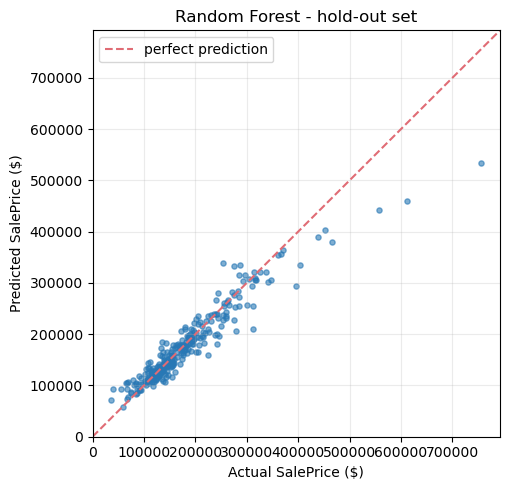

Saved individual results to: MEMBER3


In [4]:
pred_log = search.best_estimator_.predict(X_hold)
actual, predicted = np.expm1(y_hold), np.expm1(pred_log)

metrics = {
    "member_id": "MEMBER3",
    "model": "Random Forest",
    "selected_preprocessing": scaler_name,
    "best_cv_rmsle": best_cv_rmsle,
    "holdout_rmsle": float(np.sqrt(mean_squared_error(y_hold, pred_log))),
    "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
    "mae": float(mean_absolute_error(actual, predicted)),
    "r2": float(r2_score(actual, predicted)),
    "best_model_parameters": json.dumps(model_params, default=str),
}
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
cv_results = pd.DataFrame(search.cv_results_)
cv_results["params"] = cv_results["params"].map(lambda x: json.dumps(x, default=str))
cv_results.to_csv(OUTPUT_DIR / "tuning_cv_results.csv", index=False)

print(f"Hold-out RMSLE: {metrics['holdout_rmsle']:.4f}")
print(f"Hold-out RMSE : ${metrics['rmse']:,.0f}")
print(f"Hold-out MAE  : ${metrics['mae']:,.0f}")
print(f"Hold-out R2   : {metrics['r2']:.4f}")

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(actual, predicted, s=14, alpha=0.6, color="#2878B5")
lim = [0, max(actual.max(), predicted.max()) * 1.05]
ax.plot(lim, lim, "--", color="#E06C75", label="perfect prediction")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual SalePrice ($)"); ax.set_ylabel("Predicted SalePrice ($)")
ax.set_title("Random Forest - hold-out set"); ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=160)
plt.show()
print("Saved individual results to:", OUTPUT_DIR.name)

## 5. Visualize the evaluation results

The first chart compares cross-validation RMSLE with the hold-out RMSLE (a large gap would signal over-fitting or an unrepresentative split). The second shows the typical error in dollars (MAE and RMSE), and the third the residuals (actual minus predicted) to check for bias.

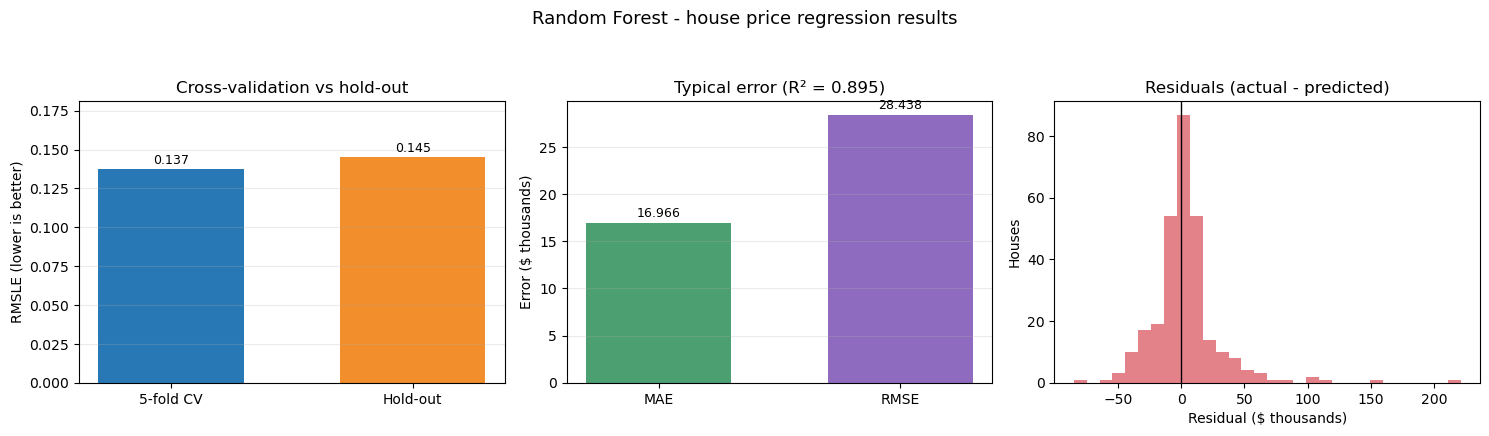

Saved metric graph to: model_metrics.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

bars = axes[0].bar(["5-fold CV", "Hold-out"], [metrics["best_cv_rmsle"], metrics["holdout_rmsle"]],
                   color=["#2878B5", "#F28E2B"], width=0.6)
axes[0].set_ylabel("RMSLE (lower is better)"); axes[0].set_title("Cross-validation vs hold-out")
axes[0].set_ylim(0, max(metrics["best_cv_rmsle"], metrics["holdout_rmsle"]) * 1.25)

bars2 = axes[1].bar(["MAE", "RMSE"], [metrics["mae"] / 1000, metrics["rmse"] / 1000],
                    color=["#4C9F70", "#8E6BBE"], width=0.6)
axes[1].set_ylabel("Error ($ thousands)"); axes[1].set_title(f"Typical error (R² = {metrics['r2']:.3f})")

residual = (actual - predicted) / 1000
axes[2].hist(residual, bins=30, color="#E06C75", alpha=0.85)
axes[2].axvline(0, color="black", lw=1)
axes[2].set_xlabel("Residual ($ thousands)"); axes[2].set_ylabel("Houses"); axes[2].set_title("Residuals (actual - predicted)")

for ax, b in zip(axes[:2], [bars, bars2]):
    ax.grid(axis="y", alpha=0.25)
    for bar in b:
        ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
fig.suptitle(f"{metrics['model']} - house price regression results", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(OUTPUT_DIR / "model_metrics.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved metric graph to:", (OUTPUT_DIR / "model_metrics.png").name)

## 6. Refit on all labelled data and predict the unlabeled `test.csv`

`test.csv` has no prices, so these predictions cannot be scored here. The final model is refit on the full training file (outlier rows removed) using the settings chosen by cross-validation.

In [6]:
keep = ~extreme_rows(X_all, y_all)
final_model = clone(search.best_estimator_).fit(X_all[keep], y_all[keep])
test_pred = np.expm1(final_model.predict(X_test))
pd.DataFrame({"Id": test_df["Id"], "SalePrice": test_pred}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Predicted", len(test_pred), "test houses. Price range: $%s - $%s" % (f"{test_pred.min():,.0f}", f"{test_pred.max():,.0f}"))
pd.DataFrame({"Id": test_df["Id"], "SalePrice": test_pred.round(0)}).head()

Predicted 1459 test houses. Price range: $53,352 - $597,077


,Id,SalePrice
0,1461,128030.0
1,1462,152583.0
2,1463,181025.0
3,1464,181536.0
4,1465,192932.0


### Interpretation

Compare the cross-validation RMSLE with the hold-out RMSLE: similar values mean the tuned model generalises to unseen houses. The residual histogram should be centred on zero; a long tail shows a few expensive houses the model under-predicts. Use the group comparison notebook to see how this model ranks against the other five.